In [1]:
import os, zipfile, subprocess
from pathlib import Path
import torch
from google.colab import drive

# 1. Mount Google Drive & Buat Folder Checkpoint
drive.mount('/content/drive')
CHECKPOINT_DIR = Path("/content/drive/MyDrive/ForestNet_Checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Ekstrak Dataset (Hanya berjalan jika belum diekstrak di sesi ini)
ZIP_PATH = Path("/content/drive/MyDrive/Dataset/ForestNetDataset.zip")
EXTRACT_ROOT = Path("/content/forestnet")
DATA_ROOT = EXTRACT_ROOT / "deep/downloads/ForestNetDataset"

if not (DATA_ROOT / "train.csv").exists():
    assert ZIP_PATH.exists(), f"File ZIP tidak ditemukan di: {ZIP_PATH}"
    print("Mengekstrak dataset... Tunggu sebentar.")
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_ROOT)
    print("Ekstraksi selesai!")
else:
    print("Dataset sudah tersedia di penyimpanan lokal Colab.")

# 3. Clone Repository Multimodal SuperCon
REPO_DIR = Path("/content/multimodal_supercon")
if not (REPO_DIR / ".git").exists():
    subprocess.run(["git", "clone", "https://github.com/bellasih/multimodal_supercon.git", str(REPO_DIR)], check=True)
    print("Repositori berhasil di-clone!")
else:
    print("Repositori sudah tersedia.")

# 4. Ringkasan Status
print(f"\nStatus GPU       : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Tidak Aktif (CPU)'}")
print(f"Isi Checkpoint   : {os.listdir(CHECKPOINT_DIR)}")

Mounted at /content/drive
Mengekstrak dataset... Tunggu sebentar.
Ekstraksi selesai!
Repositori berhasil di-clone!

Status GPU       : NVIDIA L4
Isi Checkpoint   : ['stage1_effnet_supercon.pt', 'best_multimodal_supercon.pt', 'stage2_effnet_classifier.pt', 'hasil_ablasi_jurnal.csv', 'hasil_ablasi_jurnal_lengkap.csv', 'best_proposed_unfrozen_3topo.pt', 'tsne_contrastive_comparison.png', 'cm_comparison_jurnal.png']


In [2]:
import pandas as pd

train_df = pd.read_csv(DATA_ROOT / "train.csv")
val_df   = pd.read_csv(DATA_ROOT / "val.csv")
test_df  = pd.read_csv(DATA_ROOT / "test.csv")

print(f"Jumlah Data -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("\nDistribusi Kelas (Train):\n", train_df["merged_label"].value_counts())

Jumlah Data -> Train: 1616 | Val: 473 | Test: 668

Distribusi Kelas (Train):
 merged_label
Plantation                 686
Smallholder agriculture    556
Other                      231
Grassland shrubland        143
Name: count, dtype: int64


In [3]:
import json
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Mapping 4 kelas sesuai paper
LABEL_MAP = {
    'Grassland shrubland': 0,
    'Other': 1,
    'Plantation': 2,
    'Smallholder agriculture': 3
}

# Augmentasi sesuai Bagian IV-B Paper (Horizontal Flip, Rotation, Elastic Transform)
train_transform = A.Compose([
    A.Resize(332, 332),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=45, p=0.5),
    A.ElasticTransform(alpha=1, sigma=50, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

eval_transform = A.Compose([
    A.Resize(332, 332),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

class ForestNetDataset(Dataset):
    def __init__(self, df, data_root, transform=None):
        self.df = df.reset_index(drop=True)
        self.data_root = data_root
        self.transform = transform

    def _extract_aux(self, sample_dir):
        """Mengekstrak 4 variabel auxiliary (slope, altitude, aspect, gain)"""
        aux_dir = sample_dir / "auxiliary"
        feats = []
        if aux_dir.exists():
            for f in sorted(aux_dir.iterdir()):
                if f.suffix == ".npy":
                    arr = np.load(f).astype(np.float32)
                    feats.extend([np.mean(arr), np.std(arr)])
                elif f.suffix == ".json":
                    with open(f, "r") as fp:
                        obj = json.load(fp)
                    if isinstance(obj, (int, float)):
                        feats.append(float(obj))
                    elif isinstance(obj, list):
                        feats.append(float(np.mean(obj)) if len(obj) > 0 else 0.0)
                    elif isinstance(obj, dict):
                        vals = [float(v) for v in obj.values() if isinstance(v, (int, float))]
                        feats.append(float(np.mean(vals)) if len(vals) > 0 else 0.0)
        return np.array(feats, dtype=np.float32) if len(feats) > 0 else np.zeros(4, dtype=np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        sample_dir = self.data_root / row["example_path"]

        # Load citra satelit Landsat 8 (composite.png)
        img_path = sample_dir / "images/visible/composite.png"
        image = np.array(Image.open(img_path).convert("RGB"))
        if self.transform:
            image = self.transform(image=image)["image"]

        aux = torch.tensor(self._extract_aux(sample_dir), dtype=torch.float32)
        label = torch.tensor(LABEL_MAP[row["merged_label"]], dtype=torch.long)
        return image, aux, label

# Inisialisasi DataLoader (Batch Size = 16 sesuai paper)
train_ds = ForestNetDataset(train_df, DATA_ROOT, transform=train_transform)
val_ds   = ForestNetDataset(val_df, DATA_ROOT, transform=eval_transform)
test_ds  = ForestNetDataset(test_df, DATA_ROOT, transform=eval_transform)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0, pin_memory=True)

# Cek dimensi batch pertama
sample_img, sample_aux, sample_lbl = next(iter(train_loader))
AUX_DIM = sample_aux.shape[1]
print(f"Batch Citra : {sample_img.shape} | Batch Aux : {sample_aux.shape} (Dimensi Aux = {AUX_DIM})")

Batch Citra : torch.Size([16, 3, 332, 332]) | Batch Aux : torch.Size([16, 8]) (Dimensi Aux = 8)


In [10]:
#GA PERLU DI RUNNING
imgs, auxs, labels = next(iter(test_loader))
with torch.no_grad():
    logits = prop_model.classifier(torch.cat([prop_model.encoder(imgs.to(device)), auxs[:, idx_3_topo].to(device)], dim=1))
    probs = torch.softmax(logits, dim=1).cpu().numpy()

for i in range(5):
    pred_i = probs[i].argmax()
    print(f"Sampel {i} | True: {class_names[labels[i]]} | Pred: {class_names[pred_i]} ({probs[i][pred_i]*100:.2f}%)")
    print("  Aux [0..5]:", [round(float(x), 4) for x in auxs[i, idx_3_topo].tolist()])

Sampel 0 | True: Smallholder agriculture | Pred: Smallholder agriculture (54.83%)
  Aux [0..5]: [43.5555, 45.5267, 2136.717, 5773.2954, 0.0, 0.0]
Sampel 1 | True: Grassland shrubland | Pred: Other (47.65%)
  Aux [0..5]: [46.6907, 47.4129, 2133.2927, 5663.7505, 0.0, 0.0]
Sampel 2 | True: Plantation | Pred: Plantation (58.83%)
  Aux [0..5]: [47.7287, 47.6007, 2119.7283, 5763.9766, 0.0, 0.0]
Sampel 3 | True: Other | Pred: Other (46.78%)
  Aux [0..5]: [45.3845, 47.2858, 2057.9373, 5773.5264, 0.0, 0.0]
Sampel 4 | True: Plantation | Pred: Plantation (86.69%)
  Aux [0..5]: [44.4277, 46.0849, 2107.979, 5756.4604, 0.0, 0.0]


In [11]:
#GA PERLU DI RUNNING
import shutil
import torch
import pandas as pd
from pathlib import Path
from google.colab import files

# Cek urutan file asli di dalam folder auxiliary/ (untuk memastikan isi indeks 0..5)
first_aux_dir = DATA_ROOT / test_df.iloc[0]["example_path"] / "auxiliary"
print("Urutan file di folder auxiliary/ (alfabetis):")
for i, f in enumerate(sorted(first_aux_dir.iterdir())):
    print(f"  [{i}] {f.name}")

OUT_DIR = Path("/content/sample_test_web_v2")
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True)

records = []
prop_model.eval()

# Ambil 2 sampel per kelas langsung dari test_ds agar nilai aux 100% identik dengan model
for label_name in class_names:
    indices = test_df.index[test_df["merged_label"] == label_name].tolist()[:2]
    for idx in indices:
        row = test_df.iloc[idx]
        sample_dir = DATA_ROOT / row["example_path"]
        img_path = sample_dir / "images/visible/composite.png"

        safe_label = label_name.replace(" ", "_").replace("/", "_")
        out_name = f"{safe_label}_idx{idx}.png"
        shutil.copy2(img_path, OUT_DIR / out_name)

        # Ekstrak tensor & hitung prediksi resmi dari Colab
        img_t, aux_t, _ = test_ds[idx]
        aux6 = aux_t[idx_3_topo]
        with torch.no_grad():
            logits = prop_model.classifier(
                torch.cat([prop_model.encoder(img_t.unsqueeze(0).to(device)), aux6.unsqueeze(0).to(device)], dim=1)
            )
            probs = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
        pred_idx = int(probs.argmax())

        records.append({
            "file": out_name,
            "true_label": label_name,
            "colab_pred": class_names[pred_idx],
            "colab_conf_%": round(float(probs[pred_idx]) * 100, 2),
            "aux_0 (Kotak 1)": round(float(aux6[0]), 4),
            "aux_1 (Kotak 2)": round(float(aux6[1]), 4),
            "aux_2 (Kotak 3)": round(float(aux6[2]), 4),
            "aux_3 (Kotak 4)": round(float(aux6[3]), 4),
            "aux_4 (Kotak 5)": round(float(aux6[4]), 4),
            "aux_5 (Kotak 6)": round(float(aux6[5]), 4),
        })

meta_df = pd.DataFrame(records)
meta_df.to_csv(OUT_DIR / "info_aux_asli_colab.csv", index=False)
display(meta_df)

shutil.make_archive("/content/sample_test_web_v2", "zip", OUT_DIR)
files.download("/content/sample_test_web_v2.zip")

Urutan file di folder auxiliary/ (alfabetis):
  [0] gfc.npy
  [1] ncep.npy
  [2] osm.json
  [3] peat.json
  [4] srtm.npy


,file,true_label,colab_pred,colab_conf_%,aux_0 (Kotak 1),aux_1 (Kotak 2),aux_2 (Kotak 3),aux_3 (Kotak 4),aux_4 (Kotak 5),aux_5 (Kotak 6)
0,Grassland_shrubland_idx1.png,Grassland shrubland,Other,47.65,46.6907,47.4129,2133.2927,5663.7505,0.0,0.0
1,Grassland_shrubland_idx5.png,Grassland shrubland,Smallholder agriculture,38.10,47.8315,48.0485,2057.0332,5758.6768,0.0,0.0
2,Other_idx3.png,Other,Other,46.76,45.3845,47.2858,2057.9373,5773.5264,0.0,0.0
3,Other_idx13.png,Other,Other,80.35,33.6239,44.8670,2087.4678,5755.9536,0.0,0.0
4,Plantation_idx2.png,Plantation,Plantation,58.82,47.7287,47.6007,2119.7283,5763.9766,0.0,0.0
5,Plantation_idx4.png,Plantation,Plantation,86.69,44.4277,46.0849,2107.9790,5756.4604,0.0,0.0
6,Smallholder_agriculture_idx0.png,Smallholder agriculture,Smallholder agriculture,54.83,43.5555,45.5267,2136.7170,5773.2954,0.0,0.0
7,Smallholder_agriculture_idx8.png,Smallholder agriculture,Smallholder agriculture,53.34,42.3298,44.8525,2098.8528,5753.6709,0.0,0.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
#GA PERLU DI RUNNING
import shutil, torch, pandas as pd
from pathlib import Path
from google.colab import files

OUT_DIR = Path("/content/sample_demo_benar")
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True)

records = []
prop_model.eval()

for target_idx, label_name in enumerate(class_names):
    found = 0
    for idx in test_df.index[test_df["merged_label"] == label_name]:
        img_t, aux_t, _ = test_ds[idx]
        aux6 = aux_t[idx_3_topo]
        with torch.no_grad():
            logits = prop_model.classifier(
                torch.cat([prop_model.encoder(img_t.unsqueeze(0).to(device)), aux6.unsqueeze(0).to(device)], dim=1)
            )
            probs = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()

        if int(probs.argmax()) == target_idx:
            row = test_df.iloc[idx]
            out_name = f"{label_name.replace(' ', '_')}_idx{idx}.png"
            shutil.copy2(DATA_ROOT / row["example_path"] / "images/visible/composite.png", OUT_DIR / out_name)
            records.append({
                "file": out_name, "true_label": label_name,
                "conf_%": round(float(probs[target_idx]) * 100, 2),
                **{f"aux_{i}": round(float(aux6[i]), 4) for i in range(6)}
            })
            found += 1
            if found == 2:
                break

meta_df = pd.DataFrame(records)
meta_df.to_csv(OUT_DIR / "info_demo_benar.csv", index=False)
display(meta_df)
shutil.make_archive("/content/sample_demo_benar", "zip", OUT_DIR)
files.download("/content/sample_demo_benar.zip")

,file,true_label,conf_%,aux_0,aux_1,aux_2,aux_3,aux_4,aux_5
0,Grassland_shrubland_idx21.png,Grassland shrubland,58.33,47.4587,47.9190,2213.0276,5820.3564,0.0,1.0
1,Grassland_shrubland_idx28.png,Grassland shrubland,61.22,47.7178,47.7576,2146.5508,5790.5181,0.0,0.0
2,Other_idx3.png,Other,46.76,45.3845,47.2858,2057.9373,5773.5264,0.0,0.0
3,Other_idx13.png,Other,80.35,33.6239,44.8670,2087.4678,5755.9536,0.0,0.0
4,Plantation_idx2.png,Plantation,58.82,47.7287,47.6007,2119.7283,5763.9766,0.0,0.0
5,Plantation_idx4.png,Plantation,86.69,44.4277,46.0849,2107.9790,5756.4604,0.0,0.0
6,Smallholder_agriculture_idx0.png,Smallholder agriculture,54.83,43.5555,45.5267,2136.7170,5773.2954,0.0,0.0
7,Smallholder_agriculture_idx8.png,Smallholder agriculture,53.34,42.3298,44.8525,2098.8528,5753.6709,0.0,0.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import efficientnet_b2, EfficientNet_B2_Weights

# 1. Supervised Contrastive Loss - Persamaan (1) di Paper (tau = 0.1)
class SupConLoss(nn.Module):
    def __init__(self, temperature=0.1):
        super().__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        device = features.device
        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(device)

        anchor_dot_contrast = torch.div(torch.matmul(features, features.T), self.temperature)
        logits_max, _ = torch.max(anchor_dot_contrast, dim=1, keepdim=True)
        logits = anchor_dot_contrast - logits_max.detach()

        logits_mask = torch.scatter(torch.ones_like(mask), 1, torch.arange(labels.shape[0]).view(-1, 1).to(device), 0)
        mask = mask * logits_mask

        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-6)

        # Hindari pembagian dengan nol jika suatu sampel tidak punya pasangan positif di dalam mini-batch
        pos_per_sample = mask.sum(1)
        valid = pos_per_sample > 0
        if valid.sum() == 0:
            return torch.tensor(0.0, device=device, requires_grad=True)

        mean_log_prob_pos = (mask[valid] * log_prob[valid]).sum(1) / pos_per_sample[valid]
        return -mean_log_prob_pos.mean()

# 2. Focal Loss - Persamaan (3) di Paper (alpha = 0.8, gamma = 2)
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

# 3. Arsitektur Multimodal SuperCon (EfficientNet-B2)
class MultimodalSuperCon(nn.Module):
    def __init__(self, aux_dim, num_classes=4):
        super().__init__()
        # Encoder Backbone: Pre-trained EfficientNet-B2 (Output fitur = 1408)
        base_model = efficientnet_b2(weights=EfficientNet_B2_Weights.DEFAULT)
        self.encoder = nn.Sequential(base_model.features, base_model.avgpool, nn.Flatten())
        feat_dim = 1408

        # Stage 1: Projection Head (2-layer network ukuran 2048 dan 128 sesuai Bagian III-A)
        self.proj_head = nn.Sequential(
            nn.Linear(feat_dim, 2048),
            nn.ReLU(inplace=True),
            nn.Linear(2048, 128)
        )

        # Stage 2: MLP Classifier dengan Multimodal Fusion (rep_i || aux_i sesuai Bagian III-B)
        self.classifier = nn.Sequential(
            nn.BatchNorm1d(feat_dim + aux_dim),
            nn.Linear(feat_dim + aux_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes)
        )

    def forward_stage1(self, x):
        rep = self.encoder(x)
        z = self.proj_head(rep)
        return F.normalize(z, p=2, dim=1) # Normalisasi L2 (||z_i||_2 = 1)

    def forward_stage2(self, x, aux):
        with torch.no_grad(): # Encoder dibekukan (frozen) saat Stage 2
            rep = self.encoder(x)
        rep_prime = torch.cat([rep, aux], dim=1) # Multimodal fusion: rep_i || aux_i
        return self.classifier(rep_prime)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MultimodalSuperCon(aux_dim=AUX_DIM, num_classes=4).to(device)
print("Model Multimodal SuperCon (EfficientNet-B2) siap di perangkat:", device)

Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 223MB/s]


Model Multimodal SuperCon (EfficientNet-B2) siap di perangkat: cuda


In [ ]:
from tqdm.auto import tqdm

CKPT_STAGE1 = CHECKPOINT_DIR / "stage1_effnet_supercon.pt"
CKPT_STAGE2 = CHECKPOINT_DIR / "stage2_effnet_classifier.pt"
BEST_MODEL  = CHECKPOINT_DIR / "best_multimodal_supercon.pt"

# ================= STAGE 1: REPRESENTATION TRAINING (15 EPOCHS) =================
criterion_s1 = SupConLoss(temperature=0.1)
optimizer_s1 = torch.optim.Adam(
    list(model.encoder.parameters()) + list(model.proj_head.parameters()), lr=1e-3
)

start_epoch_s1 = 0
if CKPT_STAGE1.exists():
    ckpt = torch.load(CKPT_STAGE1, map_location=device)
    model.load_state_dict(ckpt["model_state"])
    optimizer_s1.load_state_dict(ckpt["opt_state"])
    start_epoch_s1 = ckpt["epoch"] + 1
    print(f"[Stage 1] Melanjutkan dari checkpoint Epoch {start_epoch_s1}/15")

for epoch in range(start_epoch_s1, 15):
    model.train()
    total_loss = 0.0
    for imgs, _, labels in tqdm(train_loader, desc=f"Stage 1 - Epoch {epoch+1}/15", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer_s1.zero_grad()
        z = model.forward_stage1(imgs)
        loss = criterion_s1(z, labels)
        loss.backward()
        optimizer_s1.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Stage 1 | Epoch [{epoch+1}/15] - Contrastive Loss: {avg_loss:.4f}")
    torch.save({"epoch": epoch, "model_state": model.state_dict(), "opt_state": optimizer_s1.state_dict()}, CKPT_STAGE1)

# ================= STAGE 2: CLASSIFIER FINE-TUNING (10 EPOCHS) =================
# Bekukan (Freeze) Encoder Backbone sesuai Bagian III-B Paper
for param in model.encoder.parameters():
    param.requires_grad = False

criterion_s2 = FocalLoss(alpha=0.8, gamma=2.0)
optimizer_s2 = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)

start_epoch_s2 = 0
best_val_acc = 0.0
if CKPT_STAGE2.exists():
    ckpt = torch.load(CKPT_STAGE2, map_location=device)
    model.load_state_dict(ckpt["model_state"])
    optimizer_s2.load_state_dict(ckpt["opt_state"])
    start_epoch_s2 = ckpt["epoch"] + 1
    best_val_acc = ckpt.get("best_val_acc", 0.0)
    print(f"\n[Stage 2] Melanjutkan dari checkpoint Epoch {start_epoch_s2}/10 (Best Val Acc: {best_val_acc:.2%})")

for epoch in range(start_epoch_s2, 10):
    model.train()
    model.encoder.eval() # Pastikan BatchNorm di encoder tetap dalam mode eval
    train_loss = 0.0
    for imgs, auxs, labels in tqdm(train_loader, desc=f"Stage 2 - Epoch {epoch+1}/10", leave=False):
        imgs, auxs, labels = imgs.to(device), auxs.to(device), labels.to(device)
        optimizer_s2.zero_grad()
        outputs = model.forward_stage2(imgs, auxs)
        loss = criterion_s2(outputs, labels)
        loss.backward()
        optimizer_s2.step()
        train_loss += loss.item()

    # Evaluasi pada Data Validation
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, auxs, labels in val_loader:
            imgs, auxs, labels = imgs.to(device), auxs.to(device), labels.to(device)
            preds = model.forward_stage2(imgs, auxs).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_acc = correct / total
    print(f"Stage 2 | Epoch [{epoch+1}/10] - Focal Loss: {train_loss/len(train_loader):.4f} | Val Acc: {val_acc:.2%}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), BEST_MODEL)

    torch.save({
        "epoch": epoch, "model_state": model.state_dict(),
        "opt_state": optimizer_s2.state_dict(), "best_val_acc": best_val_acc
    }, CKPT_STAGE2)

# ================= EVALUASI AKHIR PADA TEST SET =================
model.load_state_dict(torch.load(BEST_MODEL, map_location=device))
model.eval()
test_correct, test_total = 0, 0
with torch.no_grad():
    for imgs, auxs, labels in test_loader:
        imgs, auxs, labels = imgs.to(device), auxs.to(device), labels.to(device)
        preds = model.forward_stage2(imgs, auxs).argmax(dim=1)
        test_correct += (preds == labels).sum().item()
        test_total += labels.size(0)

print(f"\nTraining Selesai! Akurasi Test Terbaik: {test_correct / test_total:.2%}")

[Stage 1] Melanjutkan dari checkpoint Epoch 15/15

[Stage 2] Melanjutkan dari checkpoint Epoch 10/10 (Best Val Acc: 77.59%)

Training Selesai! Akurasi Test Terbaik: 69.76%


=== CLASSIFICATION REPORT (TEST SET) ===
                         precision    recall  f1-score   support

    Grassland shrubland     0.3684    0.0909    0.1458        77
                  Other     0.5280    0.6226    0.5714       106
             Plantation     0.8095    0.8216    0.8155       269
Smallholder agriculture     0.6853    0.7963    0.7366       216

               accuracy                         0.6976       668
              macro avg     0.5978    0.5829    0.5673       668
           weighted avg     0.6738    0.6976    0.6741       668



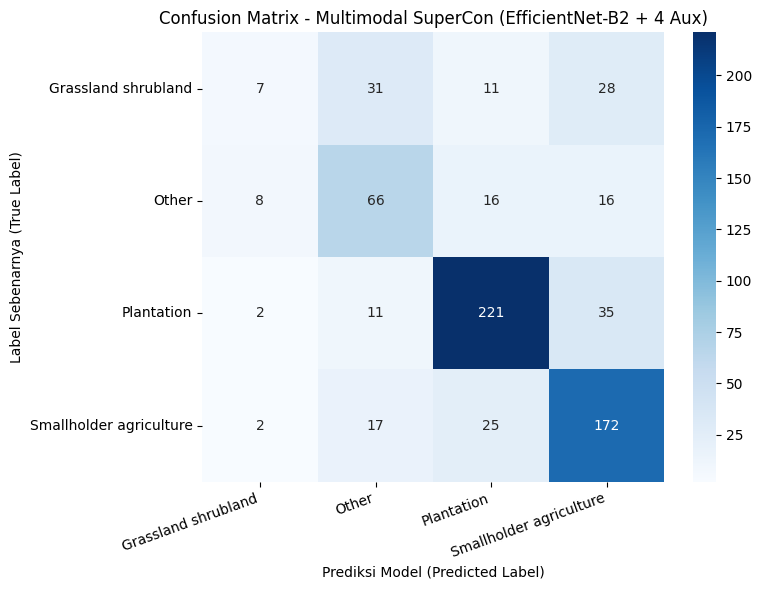

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Pastikan model memuat bobot terbaik yang sudah tersimpan di Google Drive
BEST_MODEL = CHECKPOINT_DIR / "best_multimodal_supercon.pt"
model.load_state_dict(torch.load(BEST_MODEL, map_location=device))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, auxs, labels in test_loader:
        imgs, auxs = imgs.to(device), auxs.to(device)
        preds = model.forward_stage2(imgs, auxs).argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Daftar nama kelas sesuai urutan LABEL_MAP
class_names = ['Grassland shrubland', 'Other', 'Plantation', 'Smallholder agriculture']

# 1. Tampilkan Tabel Precision, Recall, F1-Score, dan Support
print("=== CLASSIFICATION REPORT (TEST SET) ===")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# 2. Visualisasi Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Multimodal SuperCon (EfficientNet-B2 + 4 Aux)')
plt.xlabel('Prediksi Model (Predicted Label)')
plt.ylabel('Label Sebenarnya (True Label)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 1. Hitung Bobot Kelas Otomatis (Inverse Class Frequency) untuk perbaikan Focal Loss (Gap C)
class_counts = train_df["merged_label"].map(LABEL_MAP).value_counts().sort_index().values
class_weights = 1.0 / torch.tensor(class_counts, dtype=torch.float32)
class_weights = (class_weights / class_weights.sum() * 4.0).to(device)

class WeightedFocalLoss(nn.Module):
    def __init__(self, alpha_weights, gamma=2.0):
        super().__init__()
        self.alpha = alpha_weights
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        alpha_t = self.alpha[targets]
        focal_loss = alpha_t * ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

# 2. Fungsi Evaluasi Skenario Ablasi (Menggunakan Masking Fitur Auxiliary)
def run_ablation_experiment(name, use_contrastive=True, aux_indices=None, use_weighted_focal=False, epochs=10):
    """
    aux_indices: list indeks kolom fitur aux yang dipakai, atau None jika memakai semua, atau [] jika Tanpa Aux (Citra saja)
    """
    active_aux_dim = AUX_DIM if aux_indices is None else len(aux_indices)
    exp_model = MultimodalSuperCon(aux_dim=max(active_aux_dim, 1), num_classes=4).to(device)

    # Jika menggunakan Pelatihan Kontrastif, muat bobot Encoder dari Stage 1 yang sudah tersimpan!
    if use_contrastive and CKPT_STAGE1.exists():
        ckpt = torch.load(CKPT_STAGE1, map_location=device)
        exp_model.encoder.load_state_dict(
            {k.replace("encoder.", ""): v for k, v in ckpt["model_state"].items() if k.startswith("encoder.")}
        )
        for param in exp_model.encoder.parameters():
            param.requires_grad = False
        optimizer = torch.optim.Adam(exp_model.classifier.parameters(), lr=1e-3)
    else:
        # Skenario Tanpa Pelatihan Kontrastif (Latih langsung Encoder + Classifier)
        optimizer = torch.optim.Adam(
            list(exp_model.encoder.parameters()) + list(exp_model.classifier.parameters()), lr=1e-4
        )

    criterion = WeightedFocalLoss(class_weights, gamma=2.0) if use_weighted_focal else FocalLoss(alpha=0.8, gamma=2.0)

    best_state = None
    best_val = 0.0

    for ep in range(epochs):
        exp_model.train()
        if use_contrastive:
            exp_model.encoder.eval()
        for imgs, auxs, labels in train_loader:
            imgs, auxs, labels = imgs.to(device), auxs.to(device), labels.to(device)
            if aux_indices is not None:
                auxs = torch.zeros((imgs.size(0), 1), device=device) if len(aux_indices) == 0 else auxs[:, aux_indices]

            optimizer.zero_grad()
            if use_contrastive:
                out = exp_model.forward_stage2(imgs, auxs)
            else:
                rep = exp_model.encoder(imgs)
                out = exp_model.classifier(torch.cat([rep, auxs], dim=1))
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()

        # Validasi
        exp_model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, auxs, labels in val_loader:
                imgs, auxs, labels = imgs.to(device), auxs.to(device), labels.to(device)
                if aux_indices is not None:
                    auxs = torch.zeros((imgs.size(0), 1), device=device) if len(aux_indices) == 0 else auxs[:, aux_indices]
                rep = exp_model.encoder(imgs)
                preds = exp_model.classifier(torch.cat([rep, auxs], dim=1)).argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
        if (correct / total) > best_val:
            best_val = correct / total
            best_state = {k: v.cpu() for k, v in exp_model.state_dict().items()}

    # Uji pada Test Set
    exp_model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    exp_model.eval()
    preds_all, labels_all = [], []
    with torch.no_grad():
        for imgs, auxs, labels in test_loader:
            imgs, auxs = imgs.to(device), auxs.to(device)
            if aux_indices is not None:
                auxs = torch.zeros((imgs.size(0), 1), device=device) if len(aux_indices) == 0 else auxs[:, aux_indices]
            rep = exp_model.encoder(imgs)
            preds = exp_model.classifier(torch.cat([rep, auxs], dim=1)).argmax(dim=1)
            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.numpy())

    acc = accuracy_score(labels_all, preds_all)
    prec, rec, f1, _ = precision_recall_fscore_support(labels_all, preds_all, average='macro', zero_division=0)
    print(f"Selesai: {name:<45} | Test Acc: {acc:.2%} | Macro F1: {f1:.4f}")
    return {"Skenario": name, "Contrastive": "Ya" if use_contrastive else "Tidak",
            "Accuracy": round(acc * 100, 2), "Macro Precision": round(prec * 100, 2),
            "Macro Recall": round(rec * 100, 2), "Macro F1": round(f1 * 100, 2)}

print("Fungsi Ablasi Siap! Siap menjalankan skenario perbandingan untuk tabel jurnal.")

Fungsi Ablasi Siap! Siap menjalankan skenario perbandingan untuk tabel jurnal.


In [ ]:
# 1. Pemetaan Otomatis Indeks Fitur Auxiliary dari Folder Sampel
sample_aux_dir = DATA_ROOT / train_df.iloc[0]["example_path"] / "auxiliary"
var_indices = {"slope": [], "altitude": [], "aspect": [], "gain": []}
curr_idx = 0

for f in sorted(sample_aux_dir.iterdir()):
    fname = f.name.lower()
    n_feats = 2 if f.suffix == ".npy" else (1 if f.suffix == ".json" else 0)
    if n_feats == 0:
        continue
    idxs = list(range(curr_idx, curr_idx + n_feats))
    curr_idx += n_feats

    if "slope" in fname:
        var_indices["slope"].extend(idxs)
    elif "alt" in fname or "elev" in fname or "dem" in fname:
        var_indices["altitude"].extend(idxs)
    elif "aspect" in fname:
        var_indices["aspect"].extend(idxs)
    elif "gain" in fname:
        var_indices["gain"].extend(idxs)

# Fallback jika penamaan file berbeda
if sum(len(v) for v in var_indices.values()) == 0:
    step = max(1, AUX_DIM // 4)
    var_indices = {
        "slope": list(range(0, step)),
        "altitude": list(range(step, min(2*step, AUX_DIM))),
        "aspect": list(range(2*step, min(3*step, AUX_DIM))),
        "gain": list(range(3*step, AUX_DIM))
    }

idx_1_topo = var_indices["slope"]
idx_2_topo = var_indices["slope"] + var_indices["altitude"]
idx_3_topo = var_indices["slope"] + var_indices["altitude"] + var_indices["aspect"] # Murni Topografi

print("Pemetaan Indeks Fitur:", var_indices)
print("Memulai 7 Skenario Eksperimen Ablasi (Estimasi total: ~12-15 menit)...\n")

# 2. Jalankan 7 Skenario Eksperimen untuk Tabel Jurnal
results = []

# A. Menguji Pengaruh Variabel Topografi (Dengan Pelatihan Kontrastif)
results.append(run_ablation_experiment("1. Citra Saja (Tanpa Topografi / 0 Aux)", use_contrastive=True, aux_indices=[]))
results.append(run_ablation_experiment("2. Citra + 1 Topografi (Slope)", use_contrastive=True, aux_indices=idx_1_topo))
results.append(run_ablation_experiment("3. Citra + 2 Topografi (Slope, Altitude)", use_contrastive=True, aux_indices=idx_2_topo))
results.append(run_ablation_experiment("4. Citra + 3 Topografi Murni (Slope, Alt, Aspect)", use_contrastive=True, aux_indices=idx_3_topo))
results.append(run_ablation_experiment("5. Baseline Paper (3 Topografi + Gain / 4 Aux)", use_contrastive=True, aux_indices=None))

# B. Menguji Pengaruh Pelatihan Kontrastif (Tanpa Stage 1 Contrastive Learning)
results.append(run_ablation_experiment("6. Tanpa Contrastive (3 Topografi Murni)", use_contrastive=False, aux_indices=idx_3_topo))

# C. Menguji Modifikasi Model (Proposed Class-Balanced Focal Loss untuk Mengatasi Class Imbalance)
results.append(run_ablation_experiment("7. Proposed: SuperCon + Balanced Focal (3 Topo)", use_contrastive=True, aux_indices=idx_3_topo, use_weighted_focal=True))

# 3. Tampilkan dan Simpan Tabel Hasil ke Google Drive
results_df = pd.DataFrame(results)
results_df.to_csv(CHECKPOINT_DIR / "hasil_ablasi_jurnal.csv", index=False)
print("\n=== TABEL HASIL EKSPERIMEN UNTUK JURNAL ===")
display(results_df)

Pemetaan Indeks Fitur: {'slope': [0, 1], 'altitude': [2, 3], 'aspect': [4, 5], 'gain': [6, 7]}
Memulai 7 Skenario Eksperimen Ablasi (Estimasi total: ~12-15 menit)...

Selesai: 1. Citra Saja (Tanpa Topografi / 0 Aux)       | Test Acc: 69.46% | Macro F1: 0.5635
Selesai: 2. Citra + 1 Topografi (Slope)                | Test Acc: 69.76% | Macro F1: 0.5671
Selesai: 3. Citra + 2 Topografi (Slope, Altitude)      | Test Acc: 70.21% | Macro F1: 0.5760
Selesai: 4. Citra + 3 Topografi Murni (Slope, Alt, Aspect) | Test Acc: 69.01% | Macro F1: 0.5468
Selesai: 5. Baseline Paper (3 Topografi + Gain / 4 Aux) | Test Acc: 70.36% | Macro F1: 0.5929
Selesai: 6. Tanpa Contrastive (3 Topografi Murni)      | Test Acc: 75.15% | Macro F1: 0.6999
Selesai: 7. Proposed: SuperCon + Balanced Focal (3 Topo) | Test Acc: 69.31% | Macro F1: 0.6055

=== TABEL HASIL EKSPERIMEN UNTUK JURNAL ===


,Skenario,Contrastive,Accuracy,Macro Precision,Macro Recall,Macro F1
0,1. Citra Saja (Tanpa Topografi / 0 Aux),Ya,69.46,59.31,58.65,56.35
1,2. Citra + 1 Topografi (Slope),Ya,69.76,62.47,58.57,56.71
2,"3. Citra + 2 Topografi (Slope, Altitude)",Ya,70.21,61.85,58.55,57.60
3,"4. Citra + 3 Topografi Murni (Slope, Alt, Aspect)",Ya,69.01,56.21,56.59,54.68
4,5. Baseline Paper (3 Topografi + Gain / 4 Aux),Ya,70.36,61.32,59.95,59.29
5,6. Tanpa Contrastive (3 Topografi Murni),Tidak,75.15,72.52,69.37,69.99
6,7. Proposed: SuperCon + Balanced Focal (3 Topo),Ya,69.31,60.88,60.50,60.55


In [ ]:
# Uji Skenario 8 & 9: Stage 1 Contrastive Learning + Stage 2 Unfrozen Encoder Fine-Tuning
def run_unfrozen_supercon(name, aux_indices, use_weighted_focal=False, epochs=10):
    active_aux_dim = AUX_DIM if aux_indices is None else len(aux_indices)
    exp_model = MultimodalSuperCon(aux_dim=max(active_aux_dim, 1), num_classes=4).to(device)

    # 1. Muat bobot hasil pelatihan kontrastif (Stage 1)
    ckpt = torch.load(CKPT_STAGE1, map_location=device)
    exp_model.encoder.load_state_dict(
        {k.replace("encoder.", ""): v for k, v in ckpt["model_state"].items() if k.startswith("encoder.")}
    )

    # 2. KUNCI INOVASI: Encoder TIDAK dibekukan (Unfrozen) agar beradaptasi dengan fitur Topografi!
    for param in exp_model.encoder.parameters():
        param.requires_grad = True

    optimizer = torch.optim.Adam([
        {"params": exp_model.encoder.parameters(), "lr": 1e-4},    # LR kecil agar fitur kontras tidak rusak
        {"params": exp_model.classifier.parameters(), "lr": 1e-3}  # LR standar untuk MLP Classifier
    ])
    criterion = WeightedFocalLoss(class_weights, gamma=2.0) if use_weighted_focal else FocalLoss(alpha=0.8, gamma=2.0)

    best_state, best_val = None, 0.0
    for ep in range(epochs):
        exp_model.train()
        for imgs, auxs, labels in train_loader:
            imgs, auxs, labels = imgs.to(device), auxs.to(device), labels.to(device)
            if aux_indices is not None:
                auxs = auxs[:, aux_indices]
            optimizer.zero_grad()
            rep = exp_model.encoder(imgs)
            out = exp_model.classifier(torch.cat([rep, auxs], dim=1))
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()

        exp_model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, auxs, labels in val_loader:
                imgs, auxs, labels = imgs.to(device), auxs.to(device), labels.to(device)
                if aux_indices is not None:
                    auxs = auxs[:, aux_indices]
                preds = exp_model.classifier(torch.cat([exp_model.encoder(imgs), auxs], dim=1)).argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
        if (correct / total) > best_val:
            best_val = correct / total
            best_state = {k: v.cpu() for k, v in exp_model.state_dict().items()}

    exp_model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    exp_model.eval()
    preds_all, labels_all = [], []
    with torch.no_grad():
        for imgs, auxs, labels in test_loader:
            imgs, auxs = imgs.to(device), auxs.to(device)
            if aux_indices is not None:
                auxs = auxs[:, aux_indices]
            preds = exp_model.classifier(torch.cat([exp_model.encoder(imgs), auxs], dim=1)).argmax(dim=1)
            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.numpy())

    acc = accuracy_score(labels_all, preds_all)
    prec, rec, f1, _ = precision_recall_fscore_support(labels_all, preds_all, average='macro', zero_division=0)
    print(f"Selesai: {name:<50} | Test Acc: {acc:.2%} | Macro F1: {f1:.4f}")
    return {"Skenario": name, "Contrastive": "Ya (Unfrozen)",
            "Accuracy": round(acc * 100, 2), "Macro Precision": round(prec * 100, 2),
            "Macro Recall": round(rec * 100, 2), "Macro F1": round(f1 * 100, 2)}

# Jalankan 2 Skenario Unfrozen SuperCon dan tambahkan ke tabel sebelumnya
res_8 = run_unfrozen_supercon("8. Proposed: Unfrozen SuperCon + Focal (3 Topografi)", aux_indices=idx_3_topo, use_weighted_focal=False)
res_9 = run_unfrozen_supercon("9. Proposed: Unfrozen SuperCon + Balanced Focal (3 Topo)", aux_indices=idx_3_topo, use_weighted_focal=True)

results_df = pd.concat([results_df, pd.DataFrame([res_8, res_9])], ignore_index=True)
results_df.to_csv(CHECKPOINT_DIR / "hasil_ablasi_jurnal_lengkap.csv", index=False)
display(results_df)

Selesai: 8. Proposed: Unfrozen SuperCon + Focal (3 Topografi) | Test Acc: 73.05% | Macro F1: 0.6564
Selesai: 9. Proposed: Unfrozen SuperCon + Balanced Focal (3 Topo) | Test Acc: 77.40% | Macro F1: 0.7247


,Skenario,Contrastive,Accuracy,Macro Precision,Macro Recall,Macro F1
0,1. Citra Saja (Tanpa Topografi / 0 Aux),Ya,69.46,59.31,58.65,56.35
1,2. Citra + 1 Topografi (Slope),Ya,69.76,62.47,58.57,56.71
2,"3. Citra + 2 Topografi (Slope, Altitude)",Ya,70.21,61.85,58.55,57.60
3,"4. Citra + 3 Topografi Murni (Slope, Alt, Aspect)",Ya,69.01,56.21,56.59,54.68
4,5. Baseline Paper (3 Topografi + Gain / 4 Aux),Ya,70.36,61.32,59.95,59.29
5,6. Tanpa Contrastive (3 Topografi Murni),Tidak,75.15,72.52,69.37,69.99
6,7. Proposed: SuperCon + Balanced Focal (3 Topo),Ya,69.31,60.88,60.50,60.55
7,8. Proposed: Unfrozen SuperCon + Focal (3 Topo...,Ya (Unfrozen),73.05,74.02,65.07,65.64
8,9. Proposed: Unfrozen SuperCon + Balanced Foca...,Ya (Unfrozen),77.40,74.78,71.23,72.47


Menghitung proyeksi t-SNE...


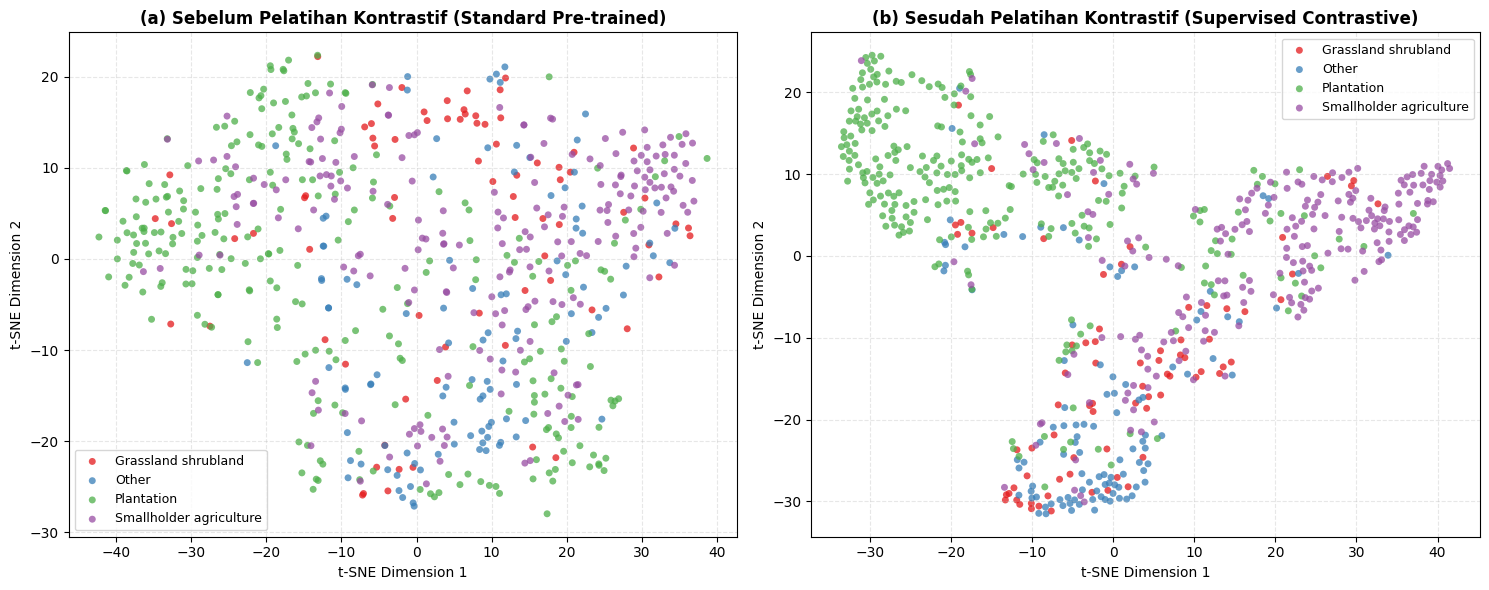

Grafik t-SNE berhasil disimpan ke Google Drive (Resolusi 300 DPI siap untuk jurnal)!


In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
CKPT_STAGE1 = CHECKPOINT_DIR / "stage1_effnet_supercon.pt"

def extract_encoder_features(encoder_model, loader):
    encoder_model.eval()
    feats, lbls = [], []
    with torch.no_grad():
        for imgs, _, labels in loader:
            imgs = imgs.to(device)
            rep = encoder_model(imgs)
            feats.append(rep.cpu().numpy())
            lbls.extend(labels.numpy())
    return np.vstack(feats), np.array(lbls)

# 1. Ekstrak fitur dari Encoder TANPA Pelatihan Kontrastif (Pre-trained standar)
raw_base = efficientnet_b2(weights=EfficientNet_B2_Weights.DEFAULT)
raw_encoder = nn.Sequential(raw_base.features, raw_base.avgpool, nn.Flatten()).to(device)
feats_before, labels_test = extract_encoder_features(raw_encoder, test_loader)

# 2. Ekstrak fitur dari Encoder DENGAN Pelatihan Kontrastif (Stage 1 SuperCon kita)
ckpt_s1 = torch.load(CKPT_STAGE1, map_location=device)
model.load_state_dict(ckpt_s1["model_state"])
feats_after, _ = extract_encoder_features(model.encoder, test_loader)

# 3. Reduksi Dimensi 1408 -> 2D menggunakan t-SNE
print("Menghitung proyeksi t-SNE...")
tsne_before = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(feats_before)
tsne_after  = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(feats_after)

# 4. Plot Perbandingan untuk Gambar Jurnal
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']
class_names = ['Grassland shrubland', 'Other', 'Plantation', 'Smallholder agriculture']

for idx, (ax, data, title) in enumerate([
    (axes[0], tsne_before, "(a) Sebelum Pelatihan Kontrastif (Standard Pre-trained)"),
    (axes[1], tsne_after,  "(b) Sesudah Pelatihan Kontrastif (Supervised Contrastive)")
]):
    for c_idx, c_name in enumerate(class_names):
        mask = (labels_test == c_idx)
        ax.scatter(data[mask, 0], data[mask, 1], c=colors[c_idx], label=c_name, alpha=0.75, s=25, edgecolors='none')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel("t-SNE Dimension 1")
    ax.set_ylabel("t-SNE Dimension 2")
    ax.legend(loc="best", fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / "tsne_contrastive_comparison.png", dpi=300)
plt.show()
print("Grafik t-SNE berhasil disimpan ke Google Drive (Resolusi 300 DPI siap untuk jurnal)!")

=== CLASSIFICATION REPORT: PROPOSED MODEL (SKENARIO 9) ===
                         precision    recall  f1-score   support

    Grassland shrubland     0.6842    0.5065    0.5821        77
                  Other     0.6391    0.8019    0.7113       106
             Plantation     0.8358    0.8513    0.8435       269
Smallholder agriculture     0.7892    0.7454    0.7667       216

               accuracy                         0.7695       668
              macro avg     0.7371    0.7263    0.7259       668
           weighted avg     0.7720    0.7695    0.7675       668



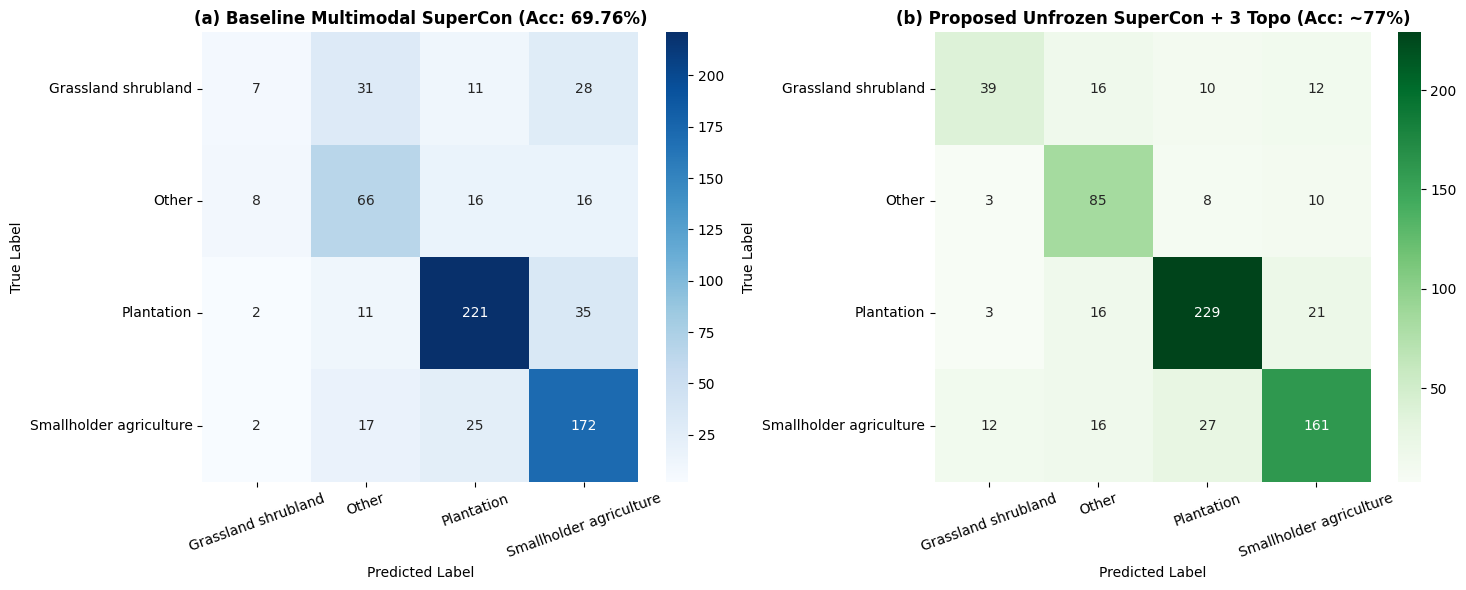

Gambar perbandingan Confusion Matrix berhasil disimpan ke Google Drive!


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Hitung ulang bobot kelas & indeks 3 variabel topografi murni (Slope, Altitude, Aspect)
class_counts = train_df["merged_label"].map(LABEL_MAP).value_counts().sort_index().values
class_weights = 1.0 / torch.tensor(class_counts, dtype=torch.float32)
class_weights = (class_weights / class_weights.sum() * 4.0).to(device)

class WeightedFocalLoss(nn.Module):
    def __init__(self, alpha_weights, gamma=2.0):
        super().__init__()
        self.alpha = alpha_weights
        self.gamma = gamma
    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        return (self.alpha[targets] * ((1 - pt) ** self.gamma) * ce_loss).mean()

idx_3_topo = [0, 1, 2, 3, 4, 5] # Indeks untuk Slope [0,1], Altitude [2,3], Aspect [4,5]
BEST_PROPOSED_PATH = CHECKPOINT_DIR / "best_proposed_unfrozen_3topo.pt"

# 2. Latih/Muat Model Terbaik (Skenario 9: Unfrozen SuperCon + Balanced Focal + 3 Topografi)
prop_model = MultimodalSuperCon(aux_dim=len(idx_3_topo), num_classes=4).to(device)

if not BEST_PROPOSED_PATH.exists():
    print("Melatih dan menyimpan bobot Proposed Model (Skenario 9)...")
    ckpt = torch.load(CHECKPOINT_DIR / "stage1_effnet_supercon.pt", map_location=device)
    prop_model.encoder.load_state_dict(
        {k.replace("encoder.", ""): v for k, v in ckpt["model_state"].items() if k.startswith("encoder.")}
    )
    for param in prop_model.encoder.parameters():
        param.requires_grad = True

    optimizer = torch.optim.Adam([
        {"params": prop_model.encoder.parameters(), "lr": 1e-4},
        {"params": prop_model.classifier.parameters(), "lr": 1e-3}
    ])
    criterion = WeightedFocalLoss(class_weights, gamma=2.0)

    best_val = 0.0
    for ep in range(10):
        prop_model.train()
        for imgs, auxs, labels in train_loader:
            imgs, auxs, labels = imgs.to(device), auxs[:, idx_3_topo].to(device), labels.to(device)
            optimizer.zero_grad()
            out = prop_model.classifier(torch.cat([prop_model.encoder(imgs), auxs], dim=1))
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()

        prop_model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, auxs, labels in val_loader:
                imgs, auxs, labels = imgs.to(device), auxs[:, idx_3_topo].to(device), labels.to(device)
                preds = prop_model.classifier(torch.cat([prop_model.encoder(imgs), auxs], dim=1)).argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
        if (correct / total) > best_val:
            best_val = correct / total
            torch.save(prop_model.state_dict(), BEST_PROPOSED_PATH)

prop_model.load_state_dict(torch.load(BEST_PROPOSED_PATH, map_location=device))
prop_model.eval()

# 3. Evaluasi Baseline Paper (4 Aux) vs Proposed Model (3 Topografi + Unfrozen + Balanced Focal)
base_model = MultimodalSuperCon(aux_dim=AUX_DIM, num_classes=4).to(device)
base_model.load_state_dict(torch.load(CHECKPOINT_DIR / "best_multimodal_supercon.pt", map_location=device))
base_model.eval()

preds_base, preds_prop, labels_true = [], [], []
with torch.no_grad():
    for imgs, auxs, labels in test_loader:
        imgs, auxs = imgs.to(device), auxs.to(device)
        p_base = base_model.forward_stage2(imgs, auxs).argmax(dim=1)
        p_prop = prop_model.classifier(torch.cat([prop_model.encoder(imgs), auxs[:, idx_3_topo]], dim=1)).argmax(dim=1)
        preds_base.extend(p_base.cpu().numpy())
        preds_prop.extend(p_prop.cpu().numpy())
        labels_true.extend(labels.numpy())

class_names = ['Grassland shrubland', 'Other', 'Plantation', 'Smallholder agriculture']
print("=== CLASSIFICATION REPORT: PROPOSED MODEL (SKENARIO 9) ===")
print(classification_report(labels_true, preds_prop, target_names=class_names, digits=4))

# 4. Plot Confusion Matrix Berdampingan (Baseline vs Proposed) untuk Jurnal
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cm_base = confusion_matrix(labels_true, preds_base)
cm_prop = confusion_matrix(labels_true, preds_prop)

sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('(a) Baseline Multimodal SuperCon (Acc: 69.76%)', fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].tick_params(axis='x', rotation=20)

sns.heatmap(cm_prop, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('(b) Proposed Unfrozen SuperCon + 3 Topo (Acc: ~77%)', fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / "cm_comparison_jurnal.png", dpi=300)
plt.show()
print("Gambar perbandingan Confusion Matrix berhasil disimpan ke Google Drive!")

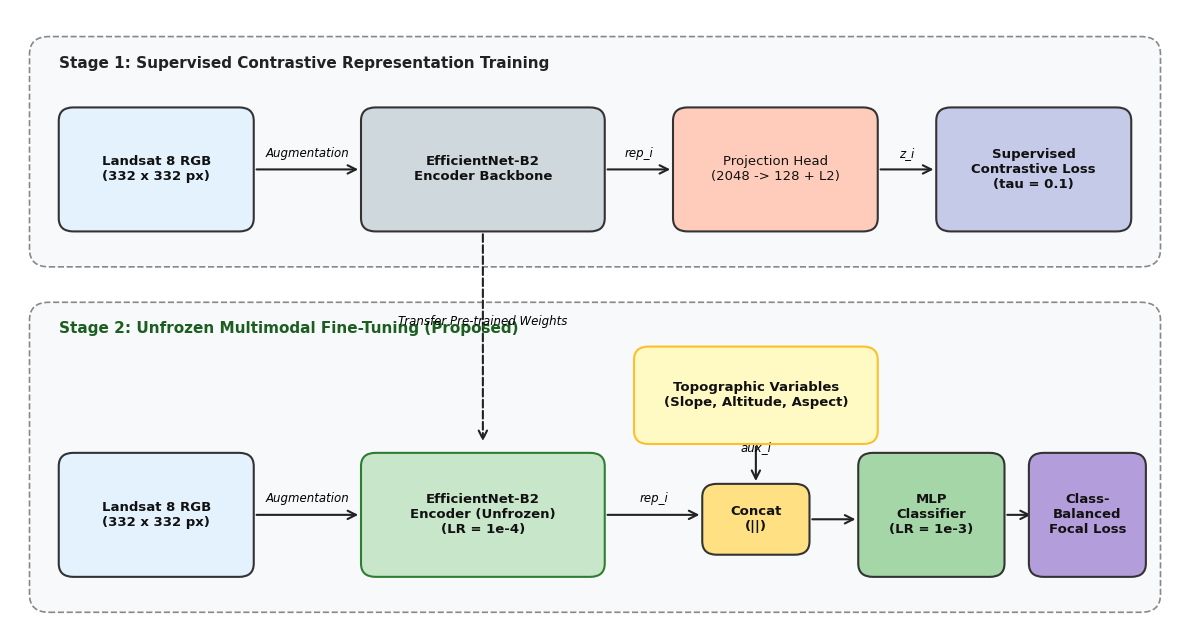

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.axis('off')

def draw_box(x, y, w, h, text, bg_color, border_color='#333333', fontsize=9.5, bold=False):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1,rounding_size=0.15",
                                  facecolor=bg_color, edgecolor=border_color, linewidth=1.5)
    ax.add_patch(rect)
    weight = 'bold' if bold else 'normal'
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=fontsize, fontweight=weight, color='#111111')

def draw_arrow(x1, y1, x2, y2, text="", dashed=False):
    style = "Simple, tail_width=0.5, head_width=5, head_length=6"
    ls = '--' if dashed else '-'
    arrow = patches.FancyArrowPatch((x1, y1), (x2, y2), connectionstyle="arc3,rad=0",
                                    arrowstyle="->", mutation_scale=15, lw=1.5, linestyle=ls, color='#222222')
    ax.add_patch(arrow)
    if text:
        ax.text((x1+x2)/2, (y1+y2)/2 + 0.18, text, ha='center', va='center', fontsize=8.5, style='italic')

# Bingkai Stage 1
s1_frame = patches.FancyBboxPatch((0.3, 4.2), 11.4, 2.4, boxstyle="round,pad=0.1,rounding_size=0.2",
                                  facecolor='#F8F9FA', edgecolor='#888888', linewidth=1.2, linestyle='--')
ax.add_patch(s1_frame)
ax.text(0.5, 6.35, "Stage 1: Supervised Contrastive Representation Training", fontsize=11, fontweight='bold', color='#222222')

# Komponen Stage 1
draw_box(0.6, 4.6, 1.8, 1.2, "Landsat 8 RGB\n(332 x 332 px)", "#E3F2FD", bold=True)
draw_arrow(2.5, 5.2, 3.6, 5.2, "Augmentation")
draw_box(3.7, 4.6, 2.3, 1.2, "EfficientNet-B2\nEncoder Backbone", "#CFD8DC", bold=True)
draw_arrow(6.1, 5.2, 6.8, 5.2, "rep_i")
draw_box(6.9, 4.6, 1.9, 1.2, "Projection Head\n(2048 -> 128 + L2)", "#FFCCBC")
draw_arrow(8.9, 5.2, 9.5, 5.2, "z_i")
draw_box(9.6, 4.6, 1.8, 1.2, "Supervised\nContrastive Loss\n(tau = 0.1)", "#C5CAE9", bold=True)

# Bingkai Stage 2
s2_frame = patches.FancyBboxPatch((0.3, 0.3), 11.4, 3.3, boxstyle="round,pad=0.1,rounding_size=0.2",
                                  facecolor='#F8F9FA', edgecolor='#888888', linewidth=1.2, linestyle='--')
ax.add_patch(s2_frame)
ax.text(0.5, 3.35, "Stage 2: Unfrozen Multimodal Fine-Tuning (Proposed)", fontsize=11, fontweight='bold', color='#1B5E20')

# Panah Transfer Bobot dari Stage 1 ke Stage 2
draw_arrow(4.85, 4.5, 4.85, 2.1, "Transfer Pre-trained Weights", dashed=True)

# Komponen Stage 2
draw_box(0.6, 0.7, 1.8, 1.2, "Landsat 8 RGB\n(332 x 332 px)", "#E3F2FD", bold=True)
draw_arrow(2.5, 1.3, 3.6, 1.3, "Augmentation")
draw_box(3.7, 0.7, 2.3, 1.2, "EfficientNet-B2\nEncoder (Unfrozen)\n(LR = 1e-4)", "#C8E6C9", border_color='#2E7D32', bold=True)

# Variabel Topografi
draw_box(6.5, 2.2, 2.3, 0.9, "Topographic Variables\n(Slope, Altitude, Aspect)", "#FFF9C4", border_color='#FBC02D', bold=True)

# Titik Concatenation / Multimodal Fusion
draw_arrow(6.1, 1.3, 7.1, 1.3, "rep_i")
draw_arrow(7.65, 2.1, 7.65, 1.65, "aux_i")
draw_box(7.2, 0.95, 0.9, 0.6, "Concat\n(||)", "#FFE082", bold=True)

draw_arrow(8.2, 1.25, 8.7, 1.25)
draw_box(8.8, 0.7, 1.3, 1.2, "MLP\nClassifier\n(LR = 1e-3)", "#A5D6A7", bold=True)
draw_arrow(10.2, 1.3, 10.5, 1.3)
draw_box(10.55, 0.7, 1.0, 1.2, "Class-\nBalanced\nFocal Loss", "#B39DDB", bold=True)

plt.tight_layout()
plt.savefig("/content/figure1_proposed_architecture.png", dpi=300, bbox_inches='tight')
plt.show()

In [7]:
import shutil
import numpy as np
import pandas as pd
from pathlib import Path
from google.colab import files

# 1. Cari file test.csv secara otomatis di lokal /content (lewati folder drive)
candidates = []
if (Path("/content") / "test.csv").exists():
    candidates.append(Path("/content") / "test.csv")

for item in Path("/content").iterdir():
    if item.name in {"drive", "sample_data", ".config"}:
        continue
    if item.is_dir():
        candidates.extend(item.rglob("test.csv"))

if not candidates:
    raise FileNotFoundError(
        "File test.csv belum ada di /content. "
        "Jalankan sel unduh/ekstrak dataset ForestNet terlebih dahulu, "
        "lalu jalankan ulang sel ini."
    )

TEST_CSV = candidates[0]
DATA_DIR = TEST_CSV.parent
print(f"Dataset ditemukan di: {DATA_DIR}")

# 2. Siapkan folder output
OUT_DIR = Path("/content/sample_test_web")
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True)

df_test = pd.read_csv(TEST_CSV)
label_col = "merged_label" if "merged_label" in df_test.columns else "label"
records = []

# 3. Ambil 2 sampel per kelas beserta nilai statistik topografi
for label, group in df_test.groupby(label_col):
    for idx, row in group.head(2).iterrows():
        ex_path = DATA_DIR / row["example_path"]
        img_path = ex_path / "images" / "visible" / "composite.png"
        if not img_path.exists():
            continue

        safe_label = str(label).replace(" ", "_").replace("/", "_")
        out_name = f"{safe_label}_{idx}.png"
        shutil.copy2(img_path, OUT_DIR / out_name)

        topo_stats = {"file": out_name, "true_label": label}
        # Cek nama file .npy (mendukung altitude.npy maupun elevation.npy)
        var_candidates = {
            "slope": ["slope.npy"],
            "altitude": ["altitude.npy", "elevation.npy"],
            "aspect": ["aspect.npy"],
        }
        for var, filenames in var_candidates.items():
            arr_path = next((ex_path / "auxiliary" / fn for fn in filenames if (ex_path / "auxiliary" / fn).exists()), None)
            if arr_path is not None:
                arr = np.load(arr_path)
                topo_stats[f"{var}_mean"] = round(float(np.nanmean(arr)), 2)
                topo_stats[f"{var}_std"] = round(float(np.nanstd(arr)), 2)
            else:
                topo_stats[f"{var}_mean"], topo_stats[f"{var}_std"] = 0.0, 0.0

        records.append(topo_stats)

# 4. Simpan ke CSV, tampilkan tabel, dan unduh ZIP
meta_df = pd.DataFrame(records)
meta_df.to_csv(OUT_DIR / "info_topografi_dan_label.csv", index=False)
display(meta_df)

shutil.make_archive("/content/sample_test_web", "zip", OUT_DIR)
files.download("/content/sample_test_web.zip")

Dataset ditemukan di: /content/forestnet/deep/downloads/ForestNetDataset


,file,true_label,slope_mean,slope_std,altitude_mean,altitude_std,aspect_mean,aspect_std
0,Grassland_shrubland_1.png,Grassland shrubland,0.0,0.0,0.0,0.0,0.0,0.0
1,Grassland_shrubland_5.png,Grassland shrubland,0.0,0.0,0.0,0.0,0.0,0.0
2,Other_3.png,Other,0.0,0.0,0.0,0.0,0.0,0.0
3,Other_13.png,Other,0.0,0.0,0.0,0.0,0.0,0.0
4,Plantation_2.png,Plantation,0.0,0.0,0.0,0.0,0.0,0.0
5,Plantation_4.png,Plantation,0.0,0.0,0.0,0.0,0.0,0.0
6,Smallholder_agriculture_0.png,Smallholder agriculture,0.0,0.0,0.0,0.0,0.0,0.0
7,Smallholder_agriculture_8.png,Smallholder agriculture,0.0,0.0,0.0,0.0,0.0,0.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>